Homework 5, problem 1, part d

In [1]:
# libraries and parameters

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

tau_E = 5.0
tau_I = 10.0
eta = 4.0
w_EE = 25.0 / 6.0
w_EI = 10.0
w_IE = 10.0

# from part a
p_I = -1.0 - np.log(9.0) / 4.0
p_E = 1.0 - 0.1 * w_EE - np.log(9.0) / 4.0

In [2]:
# sigmoidal activation function
def f(x):
    return 1.0 / (1.0 + np.exp(-eta * x))

# Wilson-Cowan non-linear ODE system
def wilson_cowan_system(t, y):
    E, I = y
    dE_dt = (-E + f(w_EE * E - w_EI * I + p_E)) / tau_E
    dI_dt = (-I + f(w_IE * E + p_I)) / tau_I
    return [dE_dt, dI_dt]

t_span = (0, 300) # time span in ms
t_eval = np.linspace(t_span[0], t_span[1], 3000) # fine evaluation grid
y0 = [0.11, 0.09]

In [3]:
sol = solve_ivp(wilson_cowan_system, t_span, y0, t_eval=t_eval, method='RK45')

t = sol.t
E = sol.y[0]
I = sol.y[1]

In [4]:
# isolate a steady-state window at the end of the simulation
late_mask = t > 200
t_late = t[late_mask]
E_late = E[late_mask]
I_late = I[late_mask]

# indices of peak firing activity
e_peak_idx, _ = find_peaks(E_late)
i_peak_idx, _ = find_peaks(I_late)

t_e_peaks = t_late[e_peak_idx]
t_i_peaks = t_late[i_peak_idx]

# numerical oscillation characteristics
numerical_period = np.mean(np.diff(t_e_peaks))
analytical_period = 12.59  # From part (b)

# average shift in time between adjacent peak pairs
time_lag = np.mean(t_i_peaks[:2] - t_e_peaks[:2])
numerical_phase_lag = (time_lag / numerical_period) * 2 * np.pi
analytical_phase_lag = 1.373  # From part (c)

print("Oscillation verification")
print(f"Numerical Period:  {numerical_period:.4f} ms (Analytical: {analytical_period:.2f} ms)")
print(f"Numerical Phase Lag: {numerical_phase_lag:.4f} rad (Analytical: {analytical_phase_lag:.3f} rad)")

Oscillation verification
Numerical Period:  12.6042 ms (Analytical: 12.59 ms)
Numerical Phase Lag: 1.3713 rad (Analytical: 1.373 rad)


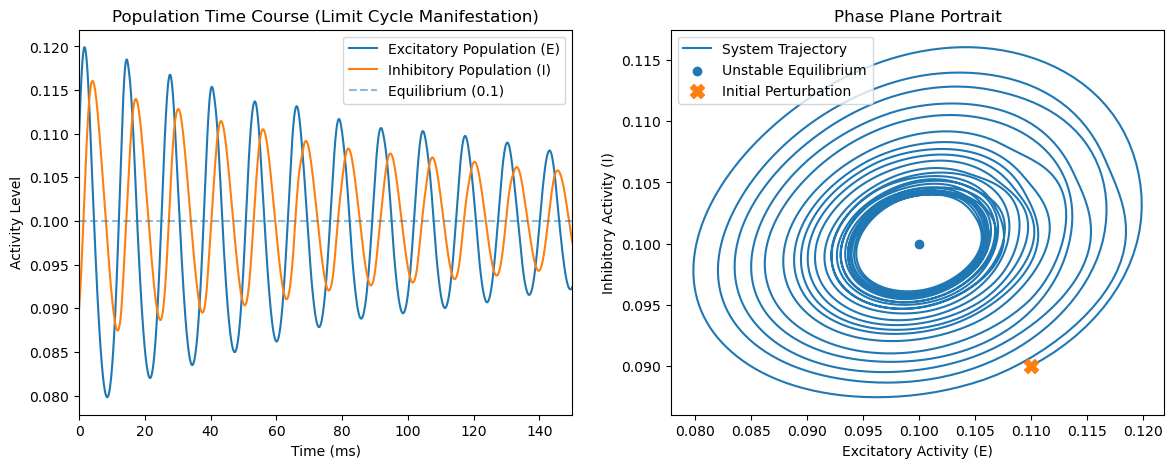

In [5]:
# plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# plot 1: time series
axes[0].plot(t, E, label = 'Excitatory Population (E)')
axes[0].plot(t, I, label = 'Inhibitory Population (I)')
axes[0].axhline(0.1, linestyle='--', alpha = 0.5, label = 'Equilibrium (0.1)')
axes[0].set_title('Population Time Course (Limit Cycle Manifestation)')
axes[0].set_xlabel('Time (ms)')
axes[0].set_ylabel('Activity Level')
axes[0].set_xlim(0, 150)
axes[0].legend(loc = 'upper right')

# plot 2: phase plane
axes[1].plot(E, I, label = 'System Trajectory')
axes[1].scatter(0.1, 0.1, zorder = 5, label = 'Unstable Equilibrium')
axes[1].scatter(y0[0], y0[1], marker='X', s = 100, zorder = 5, label = 'Initial Perturbation')
axes[1].set_title('Phase Plane Portrait')
axes[1].set_xlabel('Excitatory Activity (E)')
axes[1].set_ylabel('Inhibitory Activity (I)')
axes[1].legend()

plt.show()